
=== XRay模式（展开子图内部）===


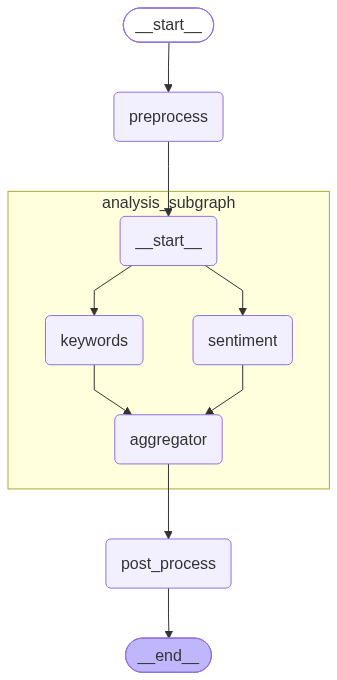

=== 测试直接嵌入子图 ===

  [父图-预处理] 收到: 这个产品真好用，我很喜欢！...
    [子图-关键词] keywords=这个产品真好用，我很喜欢！
    [子图-情感分析] sentiment=正面 😊
    [子图-合并结果] result=..
  [父图-后处理] 子图结果: 情感:正面 😊, 关键词:这个产品真好用，我很喜欢！

最终输出: ✅ 处理完成: 情感:正面 😊, 关键词:这个产品真好用，我很喜欢！


In [3]:
from typing import Annotated, TypedDict, Literal, List
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
from operator import add
from dotenv import load_dotenv

load_dotenv()
def display_graph(graph, xray=False):
    """显示图结构，xray=True 可展开子图内部结构"""
    display(Image(graph.get_graph(xray=xray).draw_mermaid_png()))
# ----- 父图: 将来直接把子图嵌入作为节点 -----
class ParentState(TypedDict):
    input_text: str     # 可共享，父调用子时直接会传递给子图
    result: str         # 子返回结果时，会直接返回给父图
    preprocessed: str
    final_output: str

# ----- 子图: 情感分析子流程（独立编译）-----
class AnalysisSubState(TypedDict):
    """子图State——除了共享key，还可以有自己的key"""
    input_text: str     # 父调用子时直接传递给子图
    result: str         # 子返回结果时，直接返回给父图
    sentiment: str      # 子图私有key
    keywords: str
# ========== 方式1: 直接嵌入 compiled subgraph ==========

def detect_sentiment(state: AnalysisSubState):
    """节点1: 检测情感"""
    text = state["input_text"]
    positive_words = ["好", "棒", "喜欢", "赞", "优秀", "nice"]
    score = sum(1 for w in positive_words if w in text)
    sentiment = "正面 😊" if score > 0 else "负面/中性 😐"
    print(f"    [子图-情感分析] sentiment={sentiment}")
    return {"sentiment": sentiment}


def extract_keywords(state: AnalysisSubState):
    """节点2: 提取关键词"""
    # 模拟实现
    text = state["input_text"]
    kw = text[:30] + ("..." if len(text) > 30 else "")
    print(f"    [子图-关键词] keywords={kw}")
    return {"keywords": kw}

def aggregator(state: AnalysisSubState):
    """节点3: 合并结果"""
    print(f"    [子图-合并结果] result=..")
    return {"result": f"情感:{state['sentiment']}, 关键词:{state['keywords']}"}

# 编译子图
analysis_subgraph = (
    StateGraph(AnalysisSubState)
    .add_node("sentiment", detect_sentiment)
    .add_node("keywords", extract_keywords)
    .add_node("aggregator", aggregator)
    .add_edge(START, "sentiment")
    .add_edge(START, "keywords")
    .add_edge("sentiment", "aggregator")
    .add_edge("keywords", "aggregator")
    .add_edge("aggregator", END)
    .compile()
)
# ----- 父图: 直接嵌入子图作为节点 -----
def preprocess(state: ParentState):
    print(f"  [父图-预处理] 收到: {state['input_text'][:40]}...")
    return {"preprocessed": state["input_text"]}

def post_process(state: ParentState):
    print(f"  [父图-后处理] 子图结果: {state['result']}")
    return {"final_output": f"✅ 处理完成: {state['result']}"}

# 🔑 关键：直接把编译好的子图传给 add_node
parent_graph = (
    StateGraph(ParentState)
    .add_node("preprocess", preprocess)
    .add_node("analysis_subgraph", analysis_subgraph)  # 子图作为节点！
    .add_node("post_process", post_process)
    .add_edge(START, "preprocess")
    .add_edge("preprocess", "analysis_subgraph")
    .add_edge("analysis_subgraph", "post_process")
    .add_edge("post_process", END)
    .compile()
)
# 用 xray 模式可以看到子图内部结构
print("\n=== XRay模式（展开子图内部）===")
display_graph(parent_graph, xray=True)
# 测试：直接嵌入子图的父图
print("=== 测试直接嵌入子图 ===\n")
r = parent_graph.invoke({
    "input_text": "这个产品真好用，我很喜欢！",
    "preprocessed": "",
    "result": "",
    "final_output": ""
})
print(f"\n最终输出: {r['final_output']}")